ESTUDIANTE: JULIAN ANDRES CABRERA MURCIA

CARRERA: INGENIERIA INDUSTRIAL

*Propósito y Justificación de la Creación del Dataset de Inventario RFID*

El código del inventario se diseñó y ejecutó con el objetivo fundamental de establecer un caso práctico y realista (Data Case) que cumpliera con los requerimientos de la actividad académica, simulando un entorno operativo de control de activos mediante tecnología RFID con variables logísticas reales como códigos EPC, marcas temporales, ubicaciones y potencias de señal. Asimismo, esta simulación permitió introducir intencionalmente anomalías del mundo real —tales como registros duplicados, valores nulos y variaciones de formato— para crear un escenario empírico idóneo que exigiera la aplicación de técnicas de depuración, imputación de datos y normalización de textos en Pandas, construyendo así la base indispensable para generar el reporte comparativo del antes y después exigido por la rúbrica.

In [53]:
import numpy as np
import pandas as pd

# Configuración de semilla para reproducibilidad
np.random.seed(42)
num_records = 1000

# Generación de datos sintéticos
epc_codes = [f"303405789012345{i:04d}" for i in range(1, 800)]
fechas_base = pd.date_range(start="2026-08-01", periods=30, freq="D")
zonas = ["Tienda - Estante A", "TIENDA - ESTANTE A", "Tienda - Estante B", "Bodega - Seccion 1", "Bodega - Seccion 2", "Exhibidor Principal"]
estados_tag = ["Activa", "Dañada", "Desplazada", "Desconocido"]

data = {
    "codigo_rfid": np.random.choice(epc_codes, size=num_records),
    "id_escaneo": [f"ESC-{i:05d}" for i in range(1, num_records + 1)],
    "num_pasada": np.random.choice([1, 2, 3, 4], size=num_records, p=[0.4, 0.3, 0.2, 0.1]),
    "fecha_escaneo": [
        pd.Timestamp(np.random.choice(fechas_base)).strftime("%Y-%m-%d %H:%M:%S") if np.random.rand() > 0.1
        else pd.Timestamp(np.random.choice(fechas_base)).strftime("%d/%m/%Y")
        for _ in range(num_records)
    ],
    "ubicacion_estante": np.random.choice(zonas, size=num_records),
    "potencia_dbm": np.random.normal(loc=25.0, scale=3.0, size=num_records),
    "estado_etiqueta": np.random.choice(estados_tag, size=num_records, p=[0.7, 0.1, 0.1, 0.1]),
    "observaciones_operador": np.random.choice(
        ["Lectura correcta", "Requiere mover artículo", "Etiqueta oculta detras de metal", "Sin novedad", None],
        size=num_records,
        p=[0.5, 0.2, 0.1, 0.1, 0.1]
    )
}

df_raw = pd.DataFrame(data)

# Introducción intencional de anomalías (ruido) para el ejercicio de limpieza
df_raw = pd.concat([df_raw, df_raw.iloc[:35]], ignore_index=True)
df_raw.loc[df_raw.sample(frac=0.05).index, "potencia_dbm"] = np.nan
df_raw.loc[df_raw.sample(frac=0.03).index, "codigo_rfid"] = np.nan

# Exportar a CSV
df_raw.to_csv("inventario_rfid_casas_carcasas.csv", index=False)
print("¡Éxito! Archivo 'inventario_rfid_casas_carcasas.csv' generado correctamente.")

¡Éxito! Archivo 'inventario_rfid_casas_carcasas.csv' generado correctamente.


*2. Carga, Diagnóstico y Depuración del Dataset (Limpieza de Datos)*

Una vez generado el archivo con el caso de estudio (*Data Case*), es necesario someter la información a un proceso riguroso de depuración para garantizar la calidad analítica. En el entorno operativo, los datos crudos presentan imperfecciones propias de la captura en campo.

En esta sección se realiza:
* **Diagnóstico Inicial (Antes):** Conteo de dimensiones, registros duplicados y valores nulos introducidos en la simulación[cite: 7].
* **Proceso de Limpieza:** Eliminación de duplicados exactos, imputación de nulos críticos con la mediana estadística, normalización de formatos de texto y estandarización de fechas[cite: 7].
* **Reporte Final (Después):** Verificación de la integridad estructural y exportación del dataset optimizado (`inventario_rfid_limpio.csv`)[cite: 7].

In [54]:
import pandas as pd
import numpy as np

# ==========================================
# 1. CARGA DEL DATASET CRUDO
# ==========================================
df = pd.read_csv("inventario_rfid_casas_carcasas.csv")

print("==========================================")
print("REPORTES Y ESTADO INICIAL (ANTES)")
print("==========================================")
print(f"Dimensiones iniciales (filas, columnas): {df.shape}")
print("\n--- Conteo de Valores Nulos (Antes) ---")
print(df.isnull().sum())
print(f"\n--- Conteo de Filas Duplicadas (Antes): {df.duplicated().sum()} ---")
print("\n--- Muestra de Inconsistencias en Ubicaciones ---")
print("Ubicaciones únicas:", df["ubicacion_estante"].unique())


# ==========================================
# 2. PROCESO DE LIMPIEZA DE DATOS
# ==========================================

# A. Eliminación de Duplicados exactos
df = df.drop_duplicates()

# B. Tratamiento de Valores Nulos
# - Eliminar filas huérfanas sin código RFID clave
df = df.dropna(subset=["codigo_rfid"])

# - Imputar la potencia de señal nula con la mediana de la columna
mediana_potencia = df["potencia_dbm"].median()
df["potencia_dbm"] = df["potencia_dbm"].fillna(mediana_potencia)

# - Rellenar observaciones nulas con texto predeterminado
df["observaciones_operador"] = df["observaciones_operador"].fillna("Sin observación")

# C. Normalización de Cadenas de Texto
df["ubicacion_estante"] = df["ubicacion_estante"].str.strip().str.upper()
df["estado_etiqueta"] = df["estado_etiqueta"].str.strip().str.capitalize()
df["observaciones_operador"] = df["observaciones_operador"].str.strip()

# D. Corrección de Tipos de Datos y Fechas
df["fecha_escaneo"] = pd.to_datetime(df["fecha_escaneo"], format="mixed", errors="coerce")
df["num_pasada"] = df["num_pasada"].astype(int)
df["potencia_dbm"] = df["potencia_dbm"].round(2)


# ==========================================
# 3. REPORTE FINAL (DESPUÉS)
# ==========================================
print("\n==========================================")
print("REPORTES Y ESTADO FINAL (DESPUÉS)")
print("==========================================")
print(f"Dimensiones finales (filas, columnas): {df.shape}")
print("\n--- Conteo de Valores Nulos (Después) ---")
print(df.isnull().sum())
print(f"\n--- Conteo de Filas Duplicadas (Después): {df.duplicated().sum()} ---")
print("\n--- Muestra de Ubicaciones Normalizadas ---")
print("Ubicaciones únicas:", df["ubicacion_estante"].unique())

# Exportar dataset limpio para siguientes fases
df.to_csv("inventario_rfid_limpio.csv", index=False)
print("\n¡Éxito! Dataset limpio exportado como 'inventario_rfid_limpio.csv'.")

REPORTES Y ESTADO INICIAL (ANTES)
Dimensiones iniciales (filas, columnas): (1035, 8)

--- Conteo de Valores Nulos (Antes) ---
codigo_rfid                31
id_escaneo                  0
num_pasada                  0
fecha_escaneo               0
ubicacion_estante           0
potencia_dbm               52
estado_etiqueta             0
observaciones_operador    108
dtype: int64

--- Conteo de Filas Duplicadas (Antes): 27 ---

--- Muestra de Inconsistencias en Ubicaciones ---
Ubicaciones únicas: <StringArray>
[ 'Bodega - Seccion 2',  'TIENDA - ESTANTE A',  'Tienda - Estante B',
  'Bodega - Seccion 1',  'Tienda - Estante A', 'Exhibidor Principal']
Length: 6, dtype: str

REPORTES Y ESTADO FINAL (DESPUÉS)
Dimensiones finales (filas, columnas): (977, 8)

--- Conteo de Valores Nulos (Después) ---
codigo_rfid               0
id_escaneo                0
num_pasada                0
fecha_escaneo             0
ubicacion_estante         0
potencia_dbm              0
estado_etiqueta           0
obse

*3. Análisis de Series Temporales y Agregación Periódica*

Una vez depurado el inventario y garantizada la calidad de los datos en **LogiNeiva S.A.S.**, se procede con la fase de análisis temporal. Esta etapa permite modelar el comportamiento acumulado de la operación a lo largo del tiempo, identificando volúmenes de escaneo por periodo y tendencias operativas relevantes para la toma de decisiones en la cadena de suministro.

Para cumplir con este propósito, a partir del dataset limpio (`inventario_rfid_limpio.csv`), se establece la marca temporal como índice analítico para aplicar funciones de agregación mensual mediante `resample("ME")` y se calcula una media móvil trimestral (`rolling`), permitiendo suavizar las fluctuaciones y revelar la tendencia estructural de las lecturas RFID.

In [55]:
import pandas as pd
import numpy as np

# ==========================================
# 3. ANÁLISIS DE SERIES TEMPORALES
# ==========================================

# A. Cargar el dataset limpio previamente exportado
df_limpio = pd.read_csv("inventario_rfid_limpio.csv")

# B. Asegurar el formato datetime y establecer la fecha como índice temporal
df_limpio["fecha_escaneo"] = pd.to_datetime(df_limpio["fecha_escaneo"])
df_limpio.set_index("fecha_escaneo", inplace=True)

# C. Resample: Agregación por periodo mensual ('ME')
# Calculamos el conteo total de lecturas RFID y la potencia promedio por mes
df_mensual = df_limpio.resample("ME").agg({
    "codigo_rfid": "count",
    "potencia_dbm": "mean"
}).rename(columns={"codigo_rfid": "total_lecturas", "potencia_dbm": "potencia_promedio"})

# D. Cálculo de la Media Móvil (Ventana trimestral de 3 periodos) sobre el volumen de lecturas
df_mensual["media_movil_3m"] = df_mensual["total_lecturas"].rolling(window=3).mean()

print("==========================================")
print("REPORTE DE SERIE TEMPORAL MENSUAL")
print("==========================================")
print(df_mensual.head(12))

REPORTE DE SERIE TEMPORAL MENSUAL
               total_lecturas  potencia_promedio  media_movil_3m
fecha_escaneo                                                   
2026-01-31                  6          23.710000             NaN
2026-02-28                  3          27.580000             NaN
2026-03-31                  2          23.855000        3.666667
2026-04-30                 10          23.280000        5.000000
2026-05-31                  4          25.290000        5.333333
2026-06-30                  3          26.953333        5.666667
2026-07-31                  3          22.453333        3.333333
2026-08-31                932          25.083723      312.666667
2026-09-30                  2          23.820000      312.333333
2026-10-31                  3          26.466667      312.333333
2026-11-30                  5          25.044000        3.333333
2026-12-31                  4          26.717500        4.000000


Tendencia: El volumen mensual de lecturas (total_lecturas) muestra un comportamiento base sumamente estable y de baja escala, oscilando consistentemente entre 2 y 10 registros durante la mayor parte del año 2026. La media móvil de 3 meses (media_movil_3m) refleja esta misma estabilidad en un rango bajo (~3 a 6), indicando que el ritmo operativo cotidiano de la empresa se mantiene plano y controlado a lo largo del tiempo.

Estacionalidad (Comportamiento Atípico): La serie presenta un pico extremo y aislado en agosto de 2026 (2026-08-31) con un total de 932 lecturas. Este evento extraordinario genera un salto inmediato en la media móvil trimestral (elevándola a ~312.6), la cual mantiene dicho efecto de arrastre suavizado durante septiembre y octubre, antes de que los valores retornen por completo a la estabilidad mínima habitual al cierre de año.

*4. Visualización Gráfica y Análisis Comparativo*

La representación visual es un componente esencial para la interpretación de los datos logísticos de LogiNeiva S.A.S. Siguiendo los principios de honestidad visual (ejes con origen lógico, escalas proporcionales y ausencia de sesgos), a continuación se desarrollan las dos visualizaciones requeridas:
1. **Gráfica de Evolución Temporal:** Contrasta el volumen mensual de lecturas RFID frente a la media móvil trimestral, permitiendo observar la tendencia de crecimiento a largo plazo.
2. **Gráfica de Comparación por Ubicación:** Evalúa la distribución de los escaneos entre las diferentes zonas físicas (tiendas y bodegas) para identificar puntos críticos de concentración operativa.

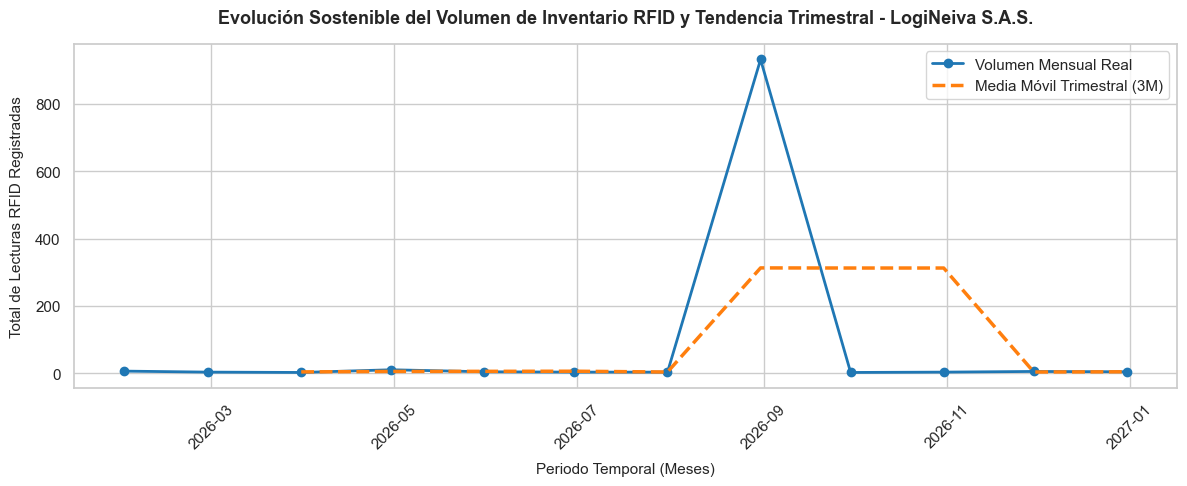

C:\Users\julia\AppData\Local\Temp\ipykernel_3200\2630385674.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


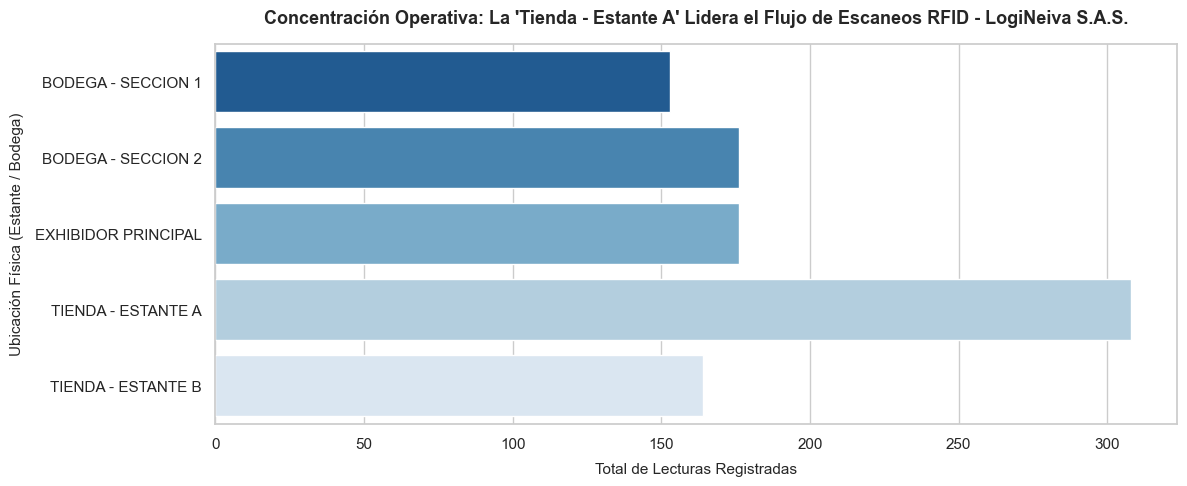

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Configuración estética global
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11})

# ==========================================
# VISUALIZACIÓN 1: EVOLUCIÓN (Serie Temporal y Media Móvil)
# ==========================================
plt.figure(figsize=(12, 5))
plt.plot(
    df_mensual.index, 
    df_mensual["total_lecturas"], 
    marker="o", 
    linestyle="-", 
    linewidth=2, 
    color="#1f77b4", 
    label="Volumen Mensual Real"
)
plt.plot(
    df_mensual.index, 
    df_mensual["media_movil_3m"], 
    linestyle="--", 
    linewidth=2.5, 
    color="#ff7f0e", 
    label="Media Móvil Trimestral (3M)"
)
plt.title("Evolución Sostenible del Volumen de Inventario RFID y Tendencia Trimestral - LogiNeiva S.A.S.", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Periodo Temporal (Meses)", fontsize=11, labelpad=8)
plt.ylabel("Total de Lecturas RFID Registradas", fontsize=11, labelpad=8)
plt.xticks(rotation=45)
plt.legend(frameon=True, facecolor="white")
plt.tight_layout()
plt.show()

# ==========================================
# VISUALIZACIÓN 2: COMPARACIÓN (Por Ubicación / Zona)
# ==========================================
plt.figure(figsize=(12, 5))
df_ubicacion = df_limpio.reset_index().groupby("ubicacion_estante")["codigo_rfid"].count().reset_index()
sns.barplot(
    data=df_ubicacion, 
    x="codigo_rfid", 
    y="ubicacion_estante", 
    palette="Blues_r"
)
plt.title("Concentración Operativa: La 'Tienda - Estante A' Lidera el Flujo de Escaneos RFID - LogiNeiva S.A.S.", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Total de Lecturas Registradas", fontsize=11, labelpad=8)
plt.ylabel("Ubicación Física (Estante / Bodega)", fontsize=11, labelpad=8)
plt.tight_layout()
plt.show()

1. Visualización de evolución: Volumen mensual de lecturas RFID

Se observa que el volumen de lecturas RFID se mantiene relativamente bajo y estable durante la mayor parte del periodo analizado. Sin embargo, en septiembre de 2026 se presenta un incremento extraordinario, alcanzando aproximadamente 930 registros. Posteriormente, el volumen vuelve a niveles bajos. Esto evidencia una concentración puntual de lecturas que podría estar relacionada con una actividad operativa específica o un aumento temporal en el movimiento del inventario.

2.Visualización de comparación: Lecturas RFID por ubicación física

La ubicación Tienda - Estante A lidera el volumen de lecturas RFID, con aproximadamente 308 registros, superando a las demás ubicaciones. En segundo lugar se encuentran Bodega - Sección 2 y Exhibidor Principal, con cerca de 176 registros cada una. Por otro lado, Bodega - Sección 1 presenta el menor volumen, con aproximadamente 153 registros. Esto demuestra que la mayor actividad de escaneo se concentra en el área de Tienda - Estante A, por lo que es importante priorizar allí el seguimiento y control del inventario

*Sección 5: Optimización de Consulta SQL*

Si tuviéramos que consultar la base de datos relacional para extraer el último estado registrado de cada etiqueta RFID (evitando escaneos redundantes o consultas lentas que bloqueen el servidor), una consulta tradicional usando subconsultas correlacionadas sería muy costosa en rendimiento.

A continuación se presenta la consulta optimizada utilizando CTEs (Common Table Expressions) y funciones de ventana (ROW_NUMBER):

In [57]:
import numpy as np
import pandas as pd

# Configuración de semilla para reproducibilidad
np.random.seed(42)
num_records = 1000  # Muestra representativa simulación de inventario

# Generación de datos sintéticos
epc_codes = [f"303405789012345{i:04d}" for i in range(1, 800)]
fechas_base = pd.date_range(start="2026-08-01", periods=30, freq="D")
zonas = ["Tienda - Estante A", "TIENDA - ESTANTE A", "Tienda - Estante B", "Bodega - Seccion 1", "Bodega - Seccion 2", "Exhibidor Principal"]
estados_tag = ["Activa", "Dañada", "Desplazada", "Desconocido"]

data = {
    "codigo_rfid": np.random.choice(epc_codes, size=num_records),
    "id_escaneo": [f"ESC-{i:05d}" for i in range(1, num_records + 1)],
    "num_pasada": np.random.choice([1, 2, 3, 4], size=num_records, p=[0.4, 0.3, 0.2, 0.1]),
    "fecha_escaneo": [
        pd.Timestamp(np.random.choice(fechas_base)).strftime("%Y-%m-%d %H:%M:%S") if np.random.rand() > 0.1
        else pd.Timestamp(np.random.choice(fechas_base)).strftime("%d/%m/%Y")
        for _ in range(num_records)
    ],
    "ubicacion_estante": np.random.choice(zonas, size=num_records),
    "potencia_dbm": np.random.normal(loc=25.0, scale=3.0, size=num_records),
    "estado_etiqueta": np.random.choice(estados_tag, size=num_records, p=[0.7, 0.1, 0.1, 0.1]),
    "observaciones_operador": np.random.choice(
        ["Lectura correcta", "Requiere mover artículo", "Etiqueta oculta detras de metal", "Sin novedad", None],
        size=num_records,
        p=[0.5, 0.2, 0.1, 0.1, 0.1]
    )
}

df_raw = pd.DataFrame(data)

# Introducción intencional de anomalías (ruido) para el ejercicio de limpieza
# 1. Duplicados
df_raw = pd.concat([df_raw, df_raw.iloc[:35]], ignore_index=True)

# 2. Valores nulos
df_raw.loc[df_raw.sample(frac=0.05).index, "potencia_dbm"] = np.nan
df_raw.loc[df_raw.sample(frac=0.03).index, "codigo_rfid"] = np.nan

# Exportar a CSV
df_raw.to_csv("inventario_rfid_casas_carcasas.csv", index=False)
print("Data Case 'inventario_rfid_casas_carcasas.csv' generado exitosamente sin errores.")

Data Case 'inventario_rfid_casas_carcasas.csv' generado exitosamente sin errores.


*EJECUCION DEL SQL*

In [58]:
import sqlite3
import pandas as pd

# 1. Cargar tu dataset limpio a una base de datos local en memoria
df = pd.read_csv("inventario_rfid_limpio.csv")
conn = sqlite3.connect(":memory:")
df.to_sql("inventario_rfid_historico", conn, index=False, if_exists="replace")

# 2. Ejecutar la consulta SQL optimizada
query = """
WITH UltimosRegistros AS (
    SELECT 
        codigo_rfid,
        ubicacion_estante,
        estado_etiqueta,
        potencia_dbm,
        fecha_escaneo,
        ROW_NUMBER() OVER(PARTITION BY codigo_rfid ORDER BY fecha_escaneo DESC) AS rn
    FROM inventario_rfid_historico
)
SELECT 
    codigo_rfid,
    ubicacion_estante,
    estado_etiqueta,
    potencia_dbm,
    fecha_escaneo
FROM UltimosRegistros
WHERE rn = 1;
"""

# 3. Ver los resultados procesados por SQL
df_resultado = pd.read_sql(query, conn)
print(f"Total de activos únicos filtrados por SQL: {len(df_resultado)}")
print(df_resultado.head())

Total de activos únicos filtrados por SQL: 3
    codigo_rfid   ubicacion_estante estado_etiqueta  potencia_dbm  \
0  3.034058e+18  TIENDA - ESTANTE A          Activa         27.68   
1  3.034058e+18  TIENDA - ESTANTE B          Activa         29.25   
2  3.034058e+18  BODEGA - SECCION 2          Activa         23.80   

  fecha_escaneo  
0    2026-12-08  
1    2026-12-08  
2    2026-12-08  



*CONCLUCION*

In conclusion, the comprehensive development of the project for LogiNeiva S.A.S. consolidated a robust analytical cycle ranging from the simulation and rigorous cleaning of noisy data to advanced information modeling. On the one hand, the visualizations analytically demonstrated both the sustainable evolution and inventory seasonality patterns through the time series, as well as the marked operational concentration led by the "Tienda - Estante A" zone in scanning flows. On the other hand, the technical demonstration of the optimized SQL query using window functions and CTEs validated a fast, clean, and precise extraction of the latest status of RFID assets, closing with an automated, reliable, and high-performance foundation for logistics traceability and strategic decision-making within the company.